In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('CIC-IoT-IDAD-Dataset-2024-balanced_dataset.csv')

In [3]:
df.head()

,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_type,Attack
0,6,291959,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1955.754061,30.826246,36494.875,57448.362362,147841.0,1.0,274175.0,68543.75,78699.844123,147841.0,533.0,125035.0,41678.333333,72187.258857,125033.0,1.0,0,0,0,0,168,136,17.125692,13.700554,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
1,6,291320,5,4,251.0,7.0,251.0,0.0,50.2,112.250612,7.0,0.0,1.75,3.5,885.624056,30.893862,36415.000,57258.196618,147430.0,1.0,273612.0,68403.00,78399.041674,147430.0,635.0,124749.0,41583.000000,72022.136680,124747.0,1.0,0,0,0,0,168,136,17.163257,13.730606,0.0,251.0,25.8,79.157789,6265.955556,2,2,0,2,8,0,0,0,0.0,28.666667,50.2,1.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
2,6,292739,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1950.542975,30.744110,36592.375,57576.745941,148188.0,1.0,274836.0,68709.00,78902.837114,148188.0,557.0,125341.0,41780.333333,72363.928040,125339.0,1.0,0,0,0,0,168,136,17.080061,13.664049,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
3,6,292398,5,4,251.0,7.0,251.0,0.0,50.2,112.250612,7.0,0.0,1.75,3.5,882.358976,30.779964,36549.750,57456.509783,147881.0,1.0,274642.0,68660.50,78638.025206,147881.0,714.0,125299.0,41766.333333,72339.679328,125297.0,1.0,0,0,0,0,168,136,17.099980,13.679984,0.0,251.0,25.8,79.157789,6265.955556,2,2,0,2,8,0,0,0,0.0,28.666667,50.2,1.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
4,6,293252,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1947.130795,30.690328,36656.500,57668.090815,148403.0,0.0,275105.0,68776.25,79019.830631,148403.0,519.0,125821.0,41940.333333,72375.351276,125512.0,0.0,0,0,0,0,168,136,17.050182,13.640146,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().any().any()

True

In [6]:
df.isnull().sum()

Protocol                       0
Flow Duration                  0
Total Fwd Packet               0
Total Bwd packets              0
Total Length of Fwd Packet     0
Total Length of Bwd Packet     0
Fwd Packet Length Max          0
Fwd Packet Length Min          0
Fwd Packet Length Mean         0
Fwd Packet Length Std          0
Bwd Packet Length Max          0
Bwd Packet Length Min          0
Bwd Packet Length Mean         0
Bwd Packet Length Std          0
Flow Bytes/s                  86
Flow Packets/s                 0
Flow IAT Mean                  0
Flow IAT Std                   0
Flow IAT Max                   0
Flow IAT Min                   0
Fwd IAT Total                  0
Fwd IAT Mean                   0
Fwd IAT Std                    0
Fwd IAT Max                    0
Fwd IAT Min                    0
Bwd IAT Total                  0
Bwd IAT Mean                   0
Bwd IAT Std                    0
Bwd IAT Max                    0
Bwd IAT Min                    0
Fwd PSH Fl

In [7]:
df.shape

(1840882, 80)

In [8]:
df = df.dropna()

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1840796 entries, 0 to 1840881
Data columns (total 80 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Protocol                    int64  
 1   Flow Duration               int64  
 2   Total Fwd Packet            int64  
 3   Total Bwd packets           int64  
 4   Total Length of Fwd Packet  float64
 5   Total Length of Bwd Packet  float64
 6   Fwd Packet Length Max       float64
 7   Fwd Packet Length Min       float64
 8   Fwd Packet Length Mean      float64
 9   Fwd Packet Length Std       float64
 10  Bwd Packet Length Max       float64
 11  Bwd Packet Length Min       float64
 12  Bwd Packet Length Mean      float64
 13  Bwd Packet Length Std       float64
 14  Flow Bytes/s                float64
 15  Flow Packets/s              float64
 16  Flow IAT Mean               float64
 17  Flow IAT Std                float64
 18  Flow IAT Max                float64
 19  Flow IAT Min              

In [10]:
df.shape

(1840796, 80)

In [11]:
df = df.drop(['Attack', 'Label'], axis=1)

In [12]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [13]:
df['Attack_type'].unique()

array(['Benign', 'BruteForce', 'DDoS', 'DoS', 'Mirai', 'Recon',
       'Spoofing', 'Web-Based'], dtype=object)

In [14]:
df = df.drop(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Bytes/Bulk Avg', 
              'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg', 'URG Flag Count', 'CWR Flag Count', 'Fwd URG Flags'], axis=1)

<h2>Outliers</h2>

In [15]:
df2 = df.copy()

In [16]:
df2['Attack_type'].unique()

array(['Benign', 'BruteForce', 'DDoS', 'DoS', 'Mirai', 'Recon',
       'Spoofing', 'Web-Based'], dtype=object)

In [17]:
attack_mapping = {
    'Benign': 0,
    'BruteForce': 1,
    'DDoS': 2,
    'DoS': 3,
    'Mirai': 4,
    'Recon': 5,
    'Spoofing': 6,
    'Web-Based': 7,
}

df2['Attack_type'] = df2['Attack_type'].apply(lambda x: attack_mapping[x])

In [18]:
df2['Attack_type'].unique()

array([0, 1, 2, 4, 5, 6, 7, 8], dtype=int64)

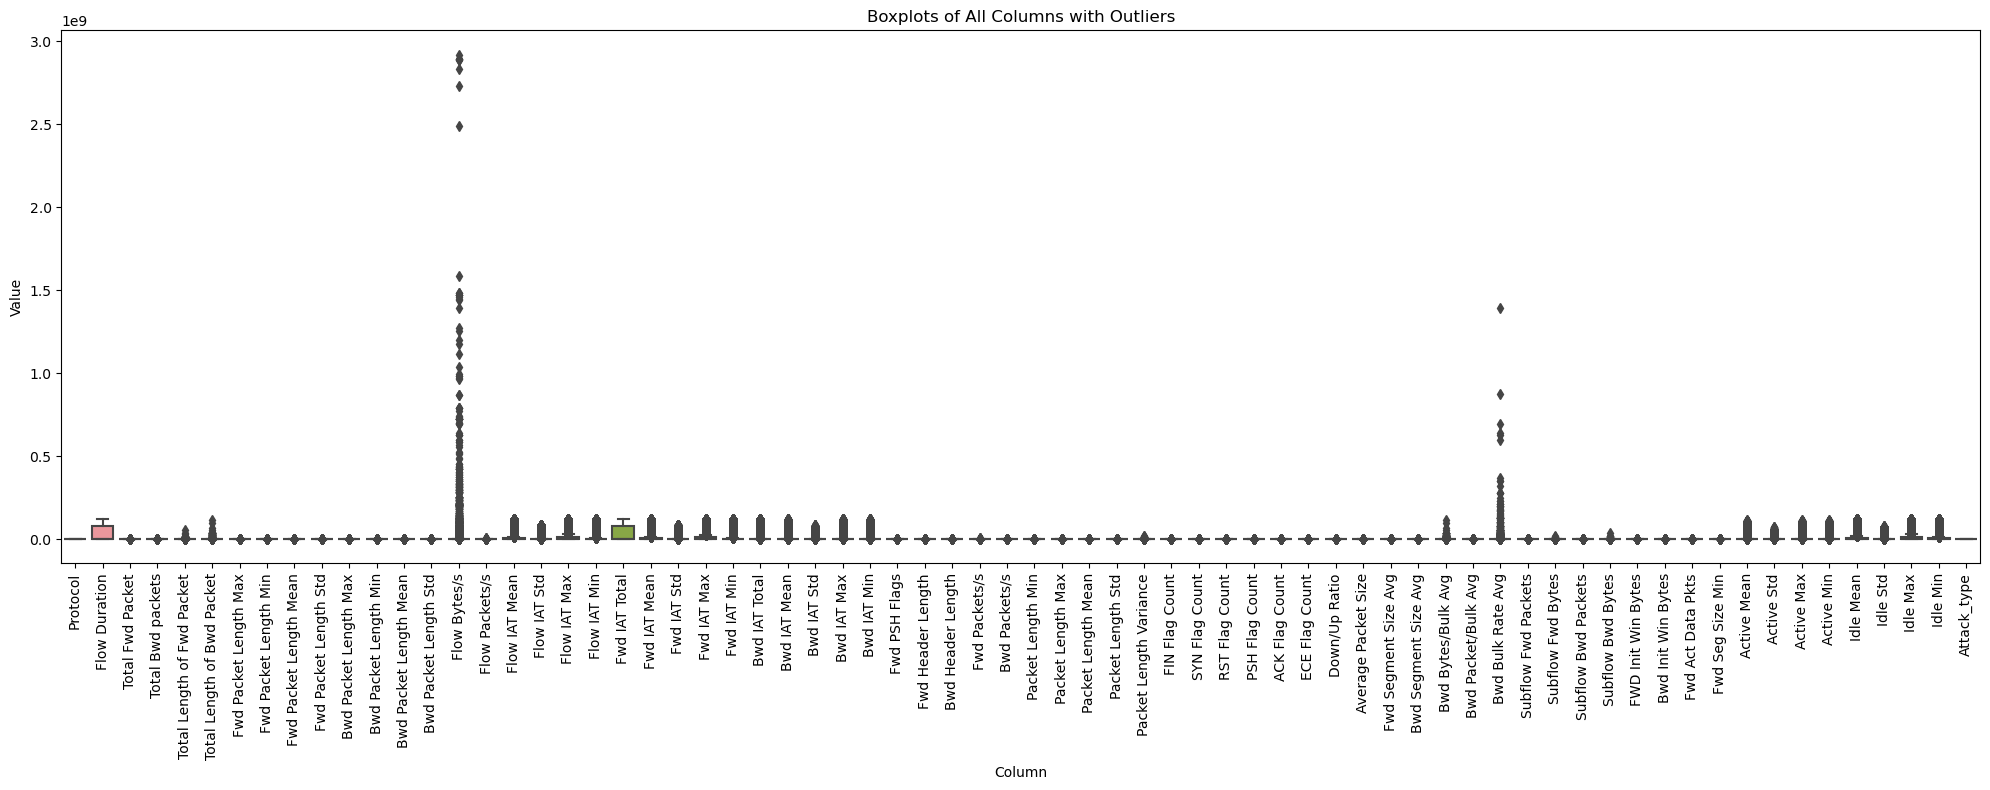

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

In [20]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [21]:
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 0,
 'Total Fwd Packet': 260322,
 'Total Bwd packets': 153470,
 'Total Length of Fwd Packet': 316514,
 'Total Length of Bwd Packet': 306249,
 'Fwd Packet Length Max': 281495,
 'Fwd Packet Length Min': 294062,
 'Fwd Packet Length Mean': 256900,
 'Fwd Packet Length Std': 399623,
 'Bwd Packet Length Max': 297008,
 'Bwd Packet Length Min': 180297,
 'Bwd Packet Length Mean': 213554,
 'Bwd Packet Length Std': 280113,
 'Flow Bytes/s': 269173,
 'Flow Packets/s': 194913,
 'Flow IAT Mean': 232054,
 'Flow IAT Std': 273983,
 'Flow IAT Max': 315334,
 'Flow IAT Min': 193157,
 'Fwd IAT Total': 0,
 'Fwd IAT Mean': 283450,
 'Fwd IAT Std': 256991,
 'Fwd IAT Max': 315519,
 'Fwd IAT Min': 229249,
 'Bwd IAT Total': 455955,
 'Bwd IAT Mean': 455981,
 'Bwd IAT Std': 380258,
 'Bwd IAT Max': 455983,
 'Bwd IAT Min': 374576,
 'Fwd PSH Flags': 95782,
 'Fwd Header Length': 219957,
 'Bwd Header Length': 292504,
 'Fwd Packets/s': 189889,
 'Bwd Packets/s': 180709,
 'Packet Length Min':

In [22]:
outliers_per_column.pop("Attack_type")
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 0,
 'Total Fwd Packet': 260322,
 'Total Bwd packets': 153470,
 'Total Length of Fwd Packet': 316514,
 'Total Length of Bwd Packet': 306249,
 'Fwd Packet Length Max': 281495,
 'Fwd Packet Length Min': 294062,
 'Fwd Packet Length Mean': 256900,
 'Fwd Packet Length Std': 399623,
 'Bwd Packet Length Max': 297008,
 'Bwd Packet Length Min': 180297,
 'Bwd Packet Length Mean': 213554,
 'Bwd Packet Length Std': 280113,
 'Flow Bytes/s': 269173,
 'Flow Packets/s': 194913,
 'Flow IAT Mean': 232054,
 'Flow IAT Std': 273983,
 'Flow IAT Max': 315334,
 'Flow IAT Min': 193157,
 'Fwd IAT Total': 0,
 'Fwd IAT Mean': 283450,
 'Fwd IAT Std': 256991,
 'Fwd IAT Max': 315519,
 'Fwd IAT Min': 229249,
 'Bwd IAT Total': 455955,
 'Bwd IAT Mean': 455981,
 'Bwd IAT Std': 380258,
 'Bwd IAT Max': 455983,
 'Bwd IAT Min': 374576,
 'Fwd PSH Flags': 95782,
 'Fwd Header Length': 219957,
 'Bwd Header Length': 292504,
 'Fwd Packets/s': 189889,
 'Bwd Packets/s': 180709,
 'Packet Length Min':

In [23]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

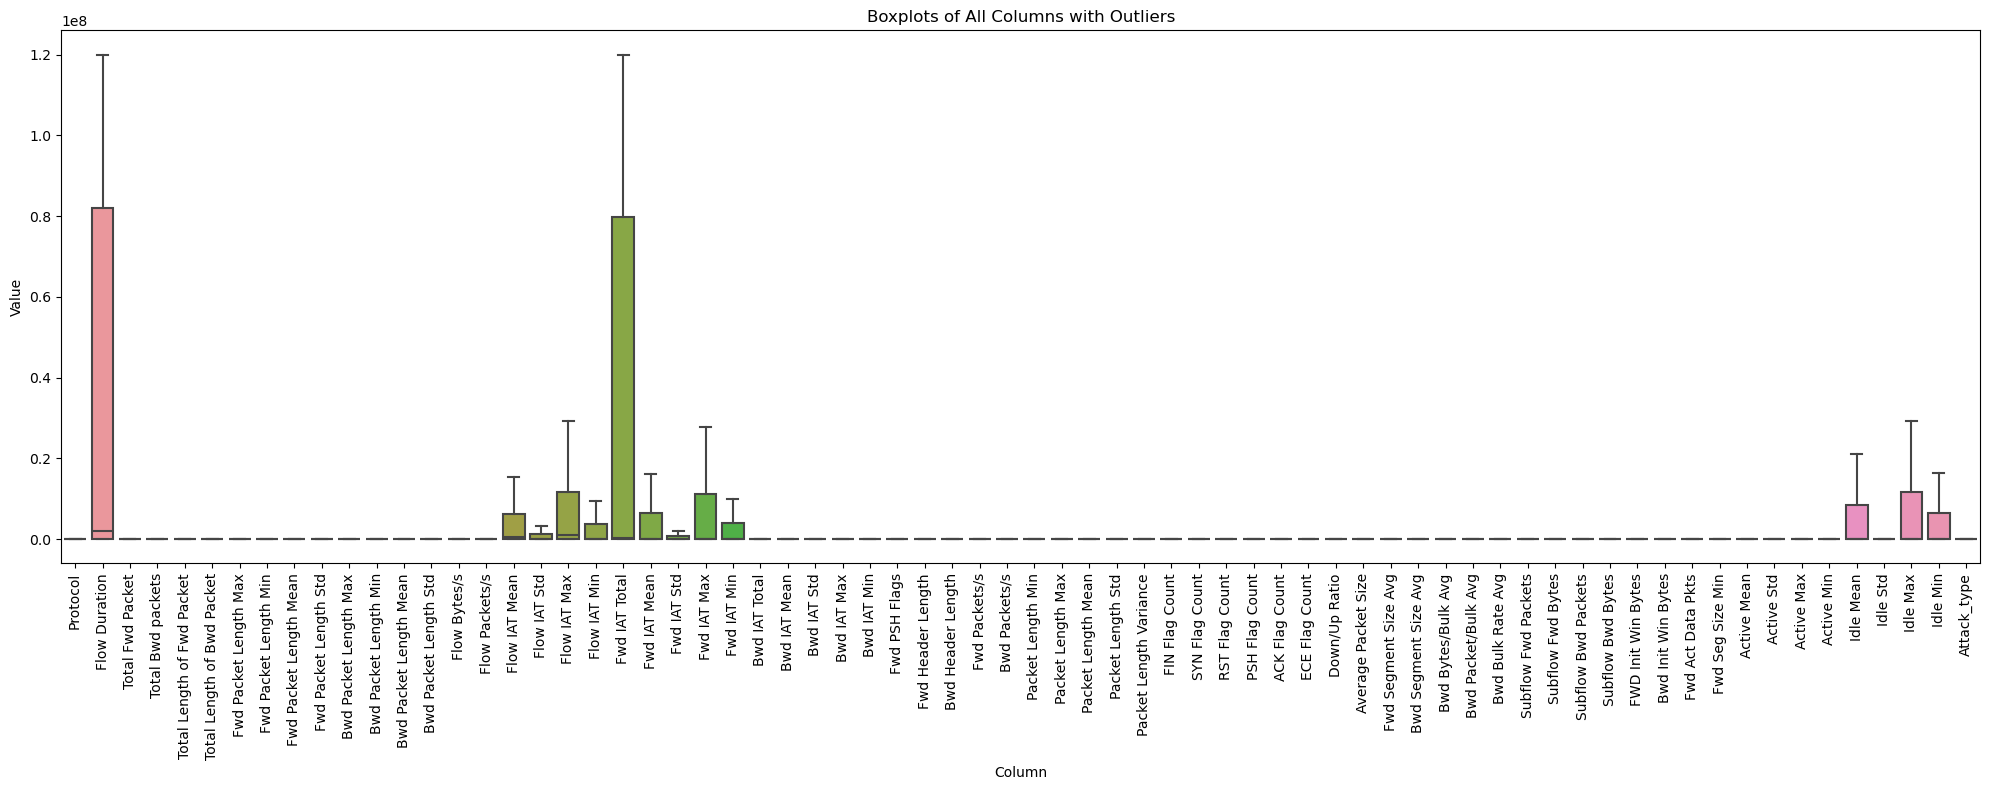

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

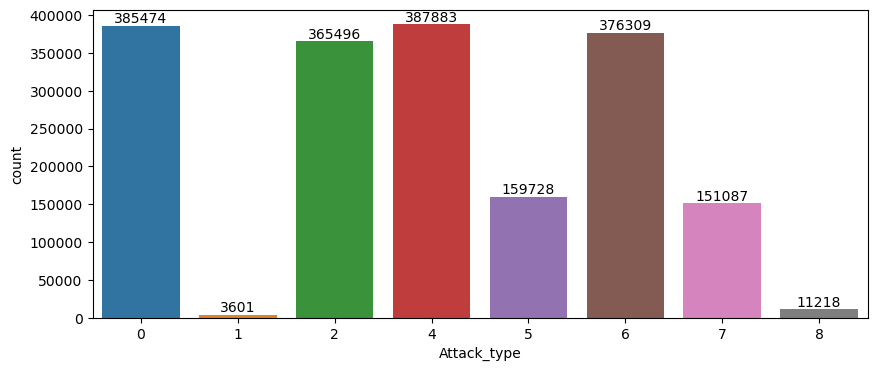

In [25]:
plt.figure(figsize=(10,4))
ax = sns.countplot(x='Attack_type',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [26]:
df2.shape

(1840796, 70)

In [27]:
df2.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
      

In [28]:
columns = ['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
       'Bwd Bytes/Bulk Avg', 'Bwd Packet/Bulk Avg', 'Bwd Bulk Rate Avg', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Act Data Pkts', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']

In [29]:
!pip install --upgrade scikit-learn
!pip install --upgrade imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB 217.9 kB/s eta 0:00:41
   ---------------------------------------- 0.1/8.9 MB 656.4 kB/s eta 0:00:14
   - -------------------------------------- 0.2/8.9 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.9 MB 2.0 MB/s eta 0:00:05
   --- ------------------------------------ 0.7/8.9 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/8.9 MB 4.6 MB/s eta 0:00:02
   -------- ------------------------------- 1.8/8.9 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/8.9 MB 5.2 MB/s eta 0:00:02
   -------------- --

  You can safely remove it manually.


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/240.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/240.0 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/240.0 kB 262.6 kB/s eta 0:00:01
   --------- ----------------------------- 61.4/240.0 kB 465.5 kB/s eta 0:00:01
   ---------------------------------- ----- 204.8/240.0 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 240.0/240.0 kB 1.2 MB/s eta 0:00:00


In [29]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Attack_type'])
y = df2['Attack_type']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Attack_type
4    310306
0    308379
6    301047
2    292397
5    127782
7    120870
8      8974
1      2881
Name: count, dtype: int64
Attack_type
6    310306
2    310306
7    310306
0    310306
4    310306
5    310306
8    310306
1    310306
Name: count, dtype: int64


<h2>ML Models</h2>

In [31]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [33]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [34]:
pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



🔹 Training Logistic Regression...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Performance:
  Accuracy:  0.6240
  Precision: 0.6238
  Recall:    0.6240
  F1-score:  0.6021

Classification Report:
               precision    recall  f1-score   support

           0       0.45      0.66      0.53     77095
           1       0.00      0.00      0.00       720
           2       0.88      0.73      0.80     73099
           4       0.82      0.90      0.86     77577
           5       0.46      0.22      0.30     31946
           6       0.52      0.61      0.57     75262
           7       0.43      0.06      0.11     30217
           8       0.00      0.00      0.00      2244

    accuracy                           0.62    368160
   macro avg       0.45      0.40      0.40    368160
weighted avg       0.62      0.62      0.60    368160



C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

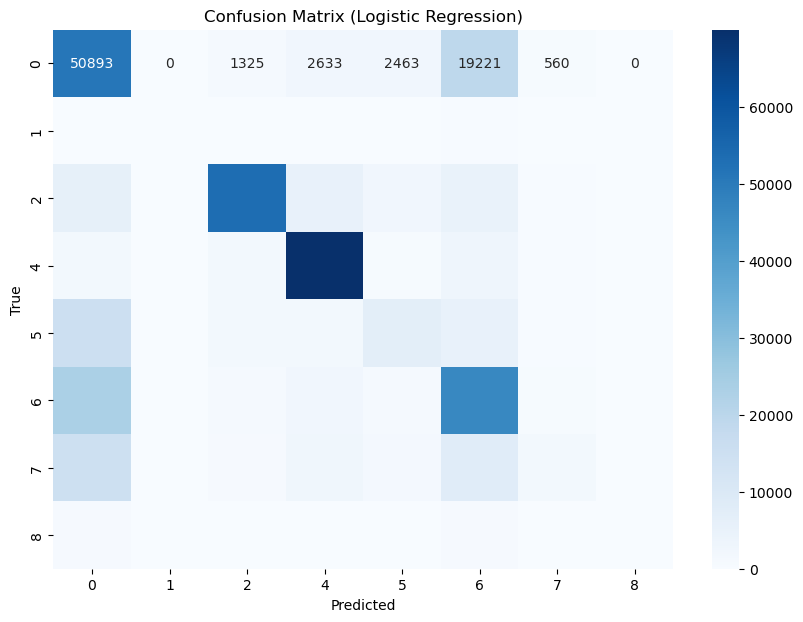


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.7721
  Precision: 0.7746
  Recall:    0.7721
  F1-score:  0.7728

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.72      0.70     77095
           1       0.18      0.13      0.15       720
           2       0.89      0.84      0.86     73099
           4       0.96      0.94      0.95     77577
           5       0.65      0.69      0.67     31946
           6       0.72      0.72      0.72     75262
           7       0.61      0.57      0.59     30217
           8       0.36      0.26      0.30      2244

    accuracy                           0.77    368160
   macro avg       0.63      0.61      0.62    368160
weighted avg       0.77      0.77      0.77    368160



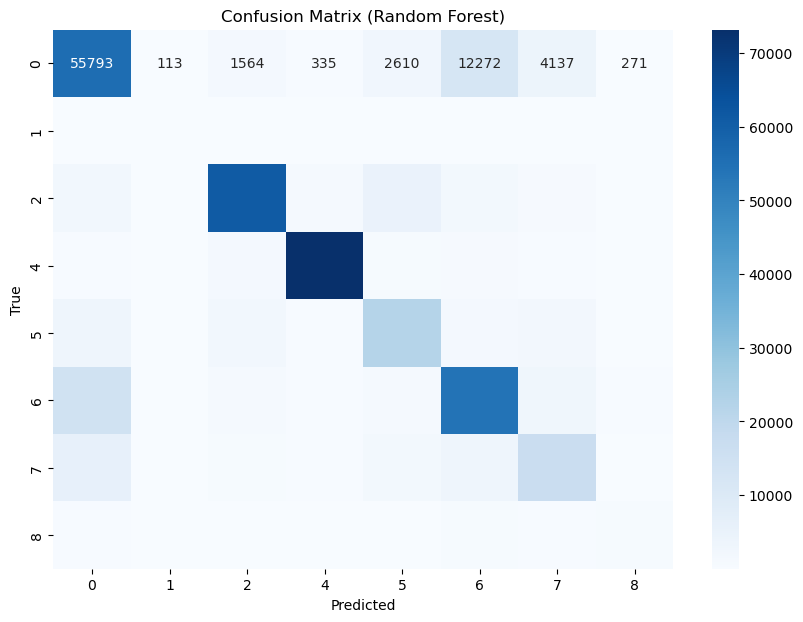


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [18:15:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.7819
  Precision: 0.8015
  Recall:    0.7819
  F1-score:  0.7803

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.87      0.72     77095
           1       0.51      0.07      0.12       720
           2       0.96      0.81      0.88     73099
           4       0.97      0.95      0.96     77577
           5       0.65      0.70      0.67     31946
           6       0.77      0.69      0.73     75262
           7       0.72      0.43      0.54     30217
           8       0.76      0.15      0.25      2244

    accuracy                           0.78    368160
   macro avg       0.74      0.58      0.61    368160
weighted avg       0.80      0.78      0.78    368160



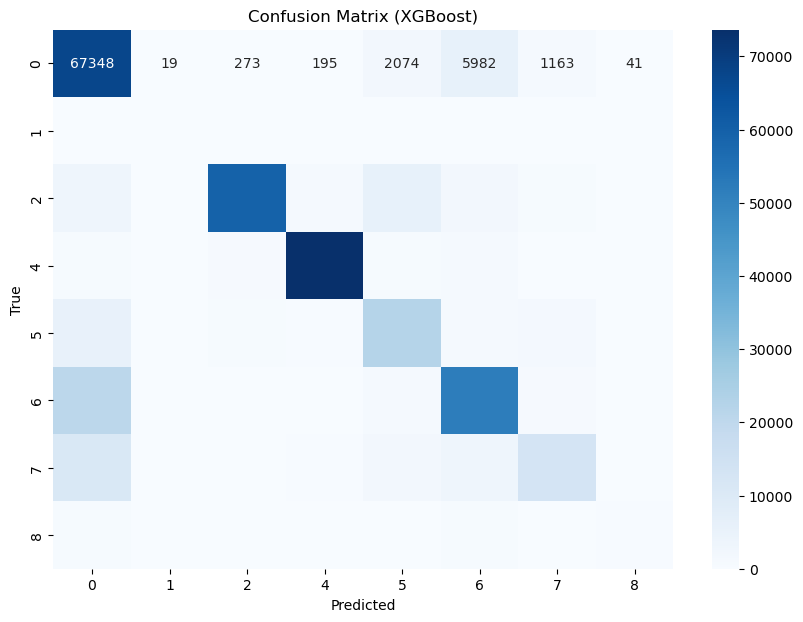


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.7669
  Precision: 0.7757
  Recall:    0.7669
  F1-score:  0.7669

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.79      0.69     77095
           1       0.31      0.12      0.18       720
           2       0.91      0.83      0.87     73099
           4       0.97      0.94      0.96     77577
           5       0.67      0.67      0.67     31946
           6       0.71      0.67      0.69     75262
           7       0.67      0.51      0.58     30217
           8       0.55      0.18      0.27      2244

    accuracy                           0.77    368160
   macro avg       0.68      0.59      0.61    368160
weighted avg       0.78      0.77      0.77    368160



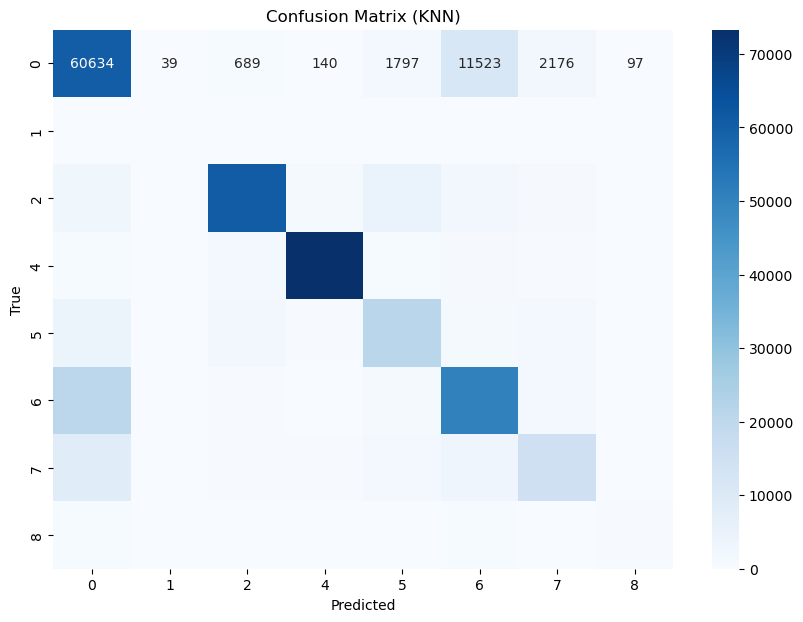


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.4043
  Precision: 0.4993
  Recall:    0.4043
  F1-score:  0.4398

Classification Report:
               precision    recall  f1-score   support

           0       0.35      0.22      0.27     77095
           1       0.00      0.64      0.01       720
           2       0.78      0.59      0.67     73099
           4       0.72      0.77      0.75     77577
           5       0.30      0.16      0.21     31946
           6       0.40      0.29      0.34     75262
           7       0.14      0.04      0.06     30217
           8       0.00      0.00      0.00      2244

    accuracy                           0.40    368160
   macro avg       0.34      0.34      0.29    368160
weighted avg       0.50      0.40      0.44    368160



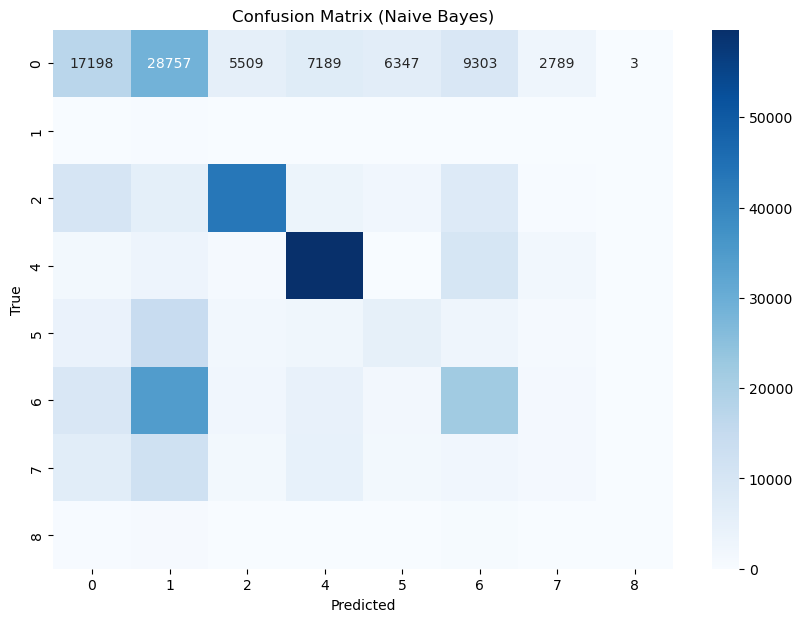


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.7089
  Precision: 0.7572
  Recall:    0.7089
  F1-score:  0.7062

Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.87      0.62     77095
           1       0.00      0.00      0.00       720
           2       0.93      0.79      0.86     73099
           4       0.97      0.93      0.95     77577
           5       0.49      0.45      0.47     31946
           6       0.83      0.56      0.67     75262
           7       0.60      0.24      0.35     30217
           8       0.81      0.02      0.04      2244

    accuracy                           0.71    368160
   macro avg       0.64      0.48      0.49    368160
weighted avg       0.76      0.71      0.71    368160



C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

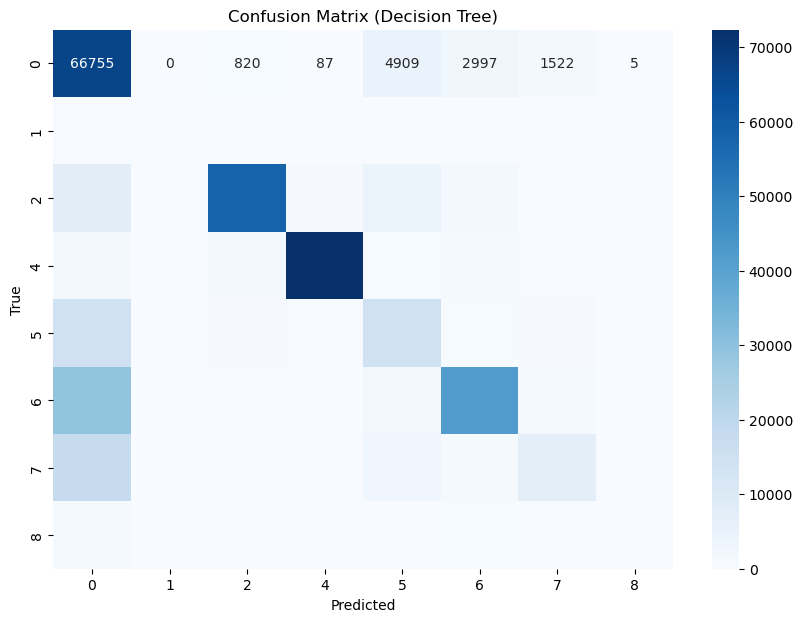


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.5694
  Precision: 0.5050
  Recall:    0.5694
  F1-score:  0.5254

Classification Report:
               precision    recall  f1-score   support

           0       0.38      0.65      0.48     77095
           1       0.00      0.00      0.00       720
           2       0.87      0.69      0.77     73099
           4       0.68      0.84      0.75     77577
           5       0.00      0.00      0.00     31946
           6       0.54      0.58      0.56     75262
           7       0.00      0.00      0.00     30217
           8       0.00      0.00      0.00      2244

    accuracy                           0.57    368160
   macro avg       0.31      0.35      0.32    368160
weighted avg       0.51      0.57      0.53    368160



C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

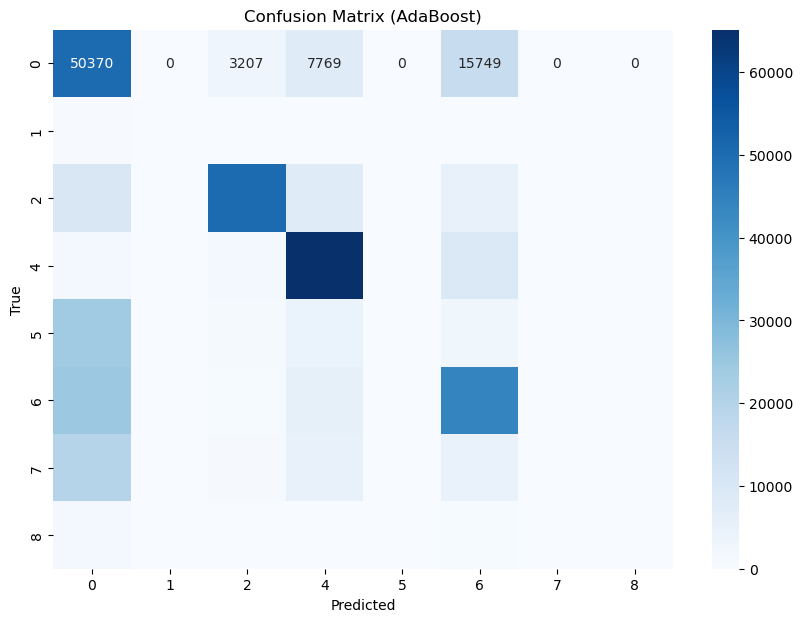


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.7631
  Precision: 0.7653
  Recall:    0.7631
  F1-score:  0.7638

Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.71      0.68     77095
           1       0.18      0.14      0.16       720
           2       0.88      0.84      0.86     73099
           4       0.95      0.94      0.95     77577
           5       0.64      0.67      0.66     31946
           6       0.71      0.70      0.70     75262
           7       0.60      0.56      0.58     30217
           8       0.34      0.26      0.30      2244

    accuracy                           0.76    368160
   macro avg       0.62      0.60      0.61    368160
weighted avg       0.77      0.76      0.76    368160



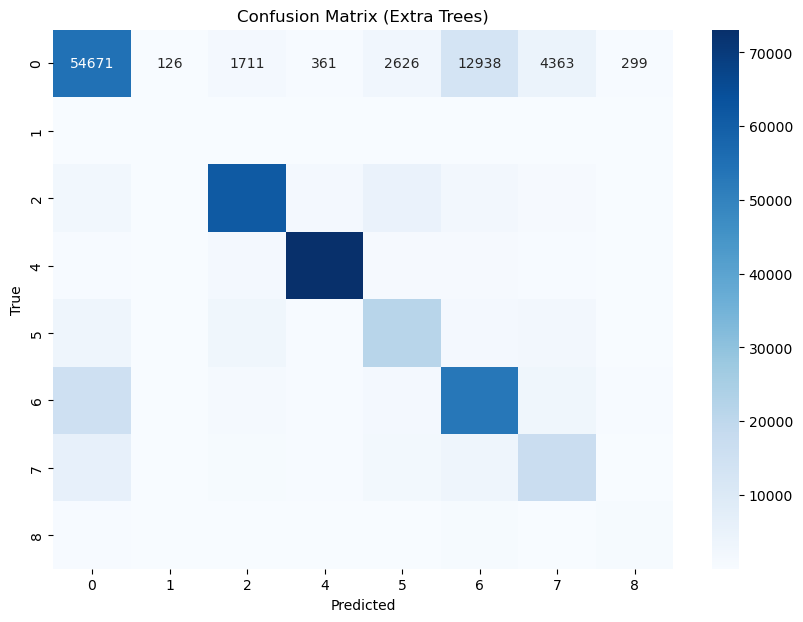


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.7844
  Precision: 0.8006
  Recall:    0.7844
  F1-score:  0.7838

Classification Report:
               precision    recall  f1-score   support

           0       0.62      0.86      0.72     77095
           1       0.16      0.10      0.13       720
           2       0.96      0.81      0.88     73099
           4       0.97      0.95      0.96     77577
           5       0.66      0.71      0.68     31946
           6       0.77      0.69      0.73     75262
           7       0.72      0.45      0.56     30217
           8       0.50      0.20      0.28      2244

    accuracy                           0.78    368160
   macro avg       0.67      0.60      0.62    368160
weighted avg       0.80      0.78      0.78    368160



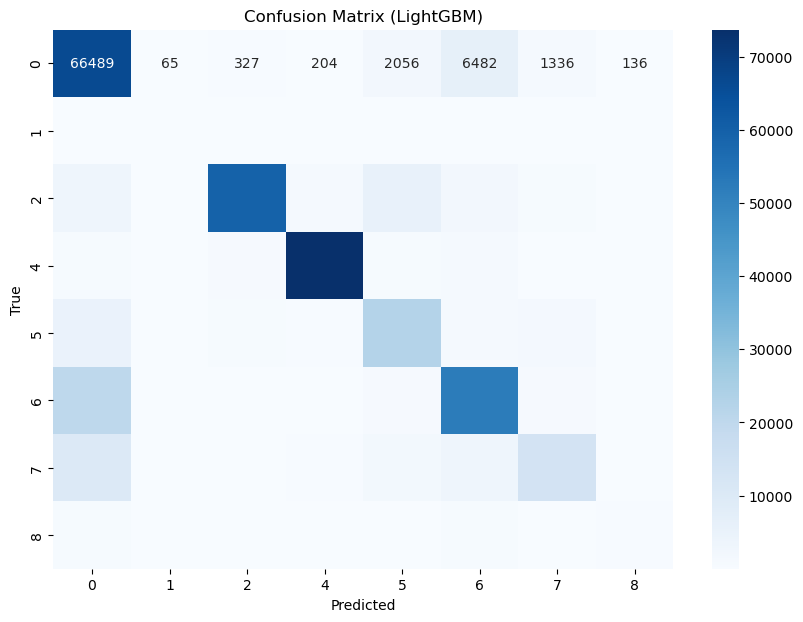


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.7526
  Precision: 0.7793
  Recall:    0.7526
  F1-score:  0.7492

Classification Report:
               precision    recall  f1-score   support

           0       0.57      0.86      0.68     77095
           1       1.00      0.02      0.04       720
           2       0.95      0.79      0.87     73099
           4       0.96      0.94      0.95     77577
           5       0.61      0.63      0.62     31946
           6       0.75      0.66      0.70     75262
           7       0.70      0.33      0.45     30217
           8       0.95      0.07      0.14      2244

    accuracy                           0.75    368160
   macro avg       0.81      0.54      0.56    368160
weighted avg       0.78      0.75      0.75    368160



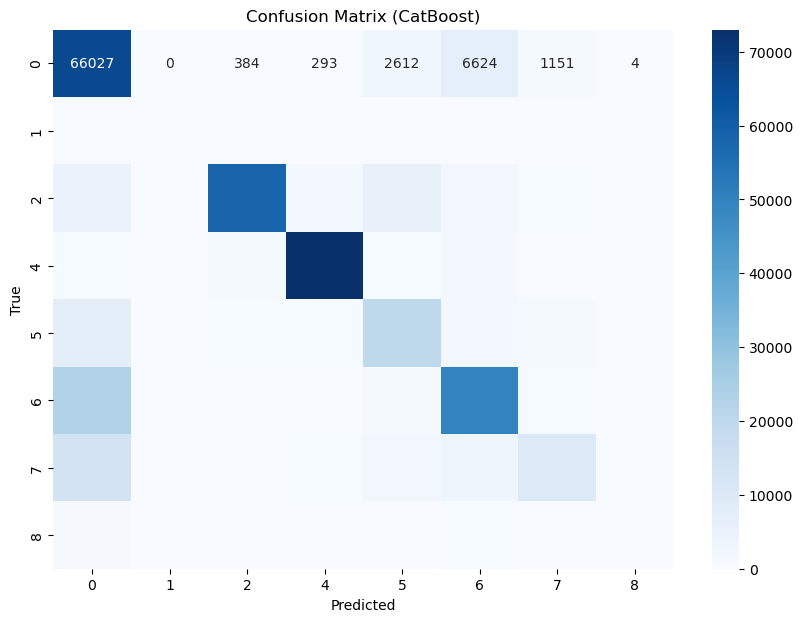


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.623990   0.623800  0.623990  0.602148
Random Forest        0.772083   0.774648  0.772083  0.772793
XGBoost              0.781853   0.801535  0.781853  0.780324
KNN                  0.766876   0.775734  0.766876  0.766940
Naive Bayes          0.404313   0.499309  0.404313  0.439826
Decision Tree        0.708898   0.757193  0.708898  0.706212
AdaBoost             0.569367   0.505044  0.569367  0.525365
Extra Trees          0.763111   0.765339  0.763111  0.763801
LightGBM             0.784368   0.800633  0.784368  0.783820
CatBoost             0.752646   0.779336  0.752646  0.749250


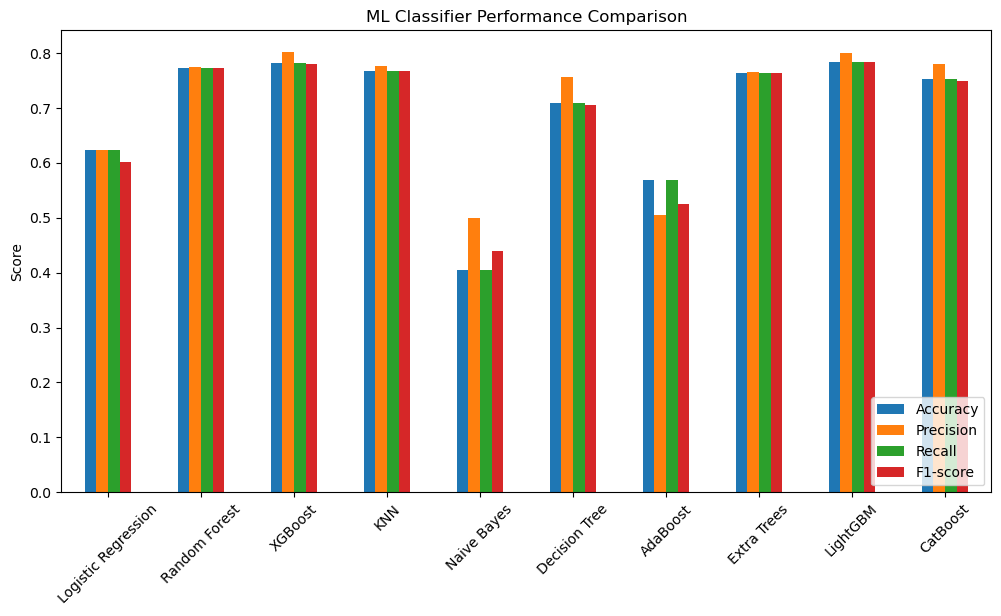

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = encoder.classes_

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"ML-Multi-Attack_type/Multiclass-ml-{name}.pdf")   # <-- save as PDF
    plt.show()


# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack_type/Multi-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\

Logistic Regression Avg Performance:
  Accuracy:  0.6247
  Precision: 0.6232
  Recall:    0.6247
  F1-score:  0.6029

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.7723
  Precision: 0.7748
  Recall:    0.7723
  F1-score:  0.7730

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:18:45] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:21:45] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:24:45] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:27:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.7830
  Precision: 0.8024
  Recall:    0.7830
  F1-score:  0.7815

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.7682
  Precision: 0.7766
  Recall:    0.7682
  F1-score:  0.7682

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.4049
  Precision: 0.5018
  Recall:    0.4049
  F1-score:  0.4408

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.7092
  Precision: 0.7551
  Recall:    0.7092
  F1-score:  0.7065

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.5692
  Precision: 0.5447
  Recall:    0.5692
  F1-score:  0.5253

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Performance:
  Accuracy:  0.7633
  Precision: 0.7655
  Recall:    0.7633
  F1-score:  0.7640

🔹 Training LightGBM with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.7844
  Precision: 0.8003
  Recall:    0.7844
  F1-score:  0.7839

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.7531
  Precision: 0.7795
  Recall:    0.7531
  F1-score:  0.7495

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.624717   0.623207  0.624717  0.602890
Random Forest        0.772285   0.774804  0.772285  0.773005
XGBoost              0.782971   0.802435  0.782971  0.781540
KNN                  0.768194   0.776635  0.768194  0.768194
Naive Bayes          0.404862   0.501770  0.404862  0.440801
Decision Tree        0.709230   0.755129  0.709230  0.706484
AdaBoost             0.569245   0.544659  0.569245  0.525268
Extra Trees          0.763336   0.765488  0.763336  0.764012
LightGBM             0.784389   0.800332  0.784389  0.783916
CatBoost             0.753083   0.779471  0.753083  0.749538


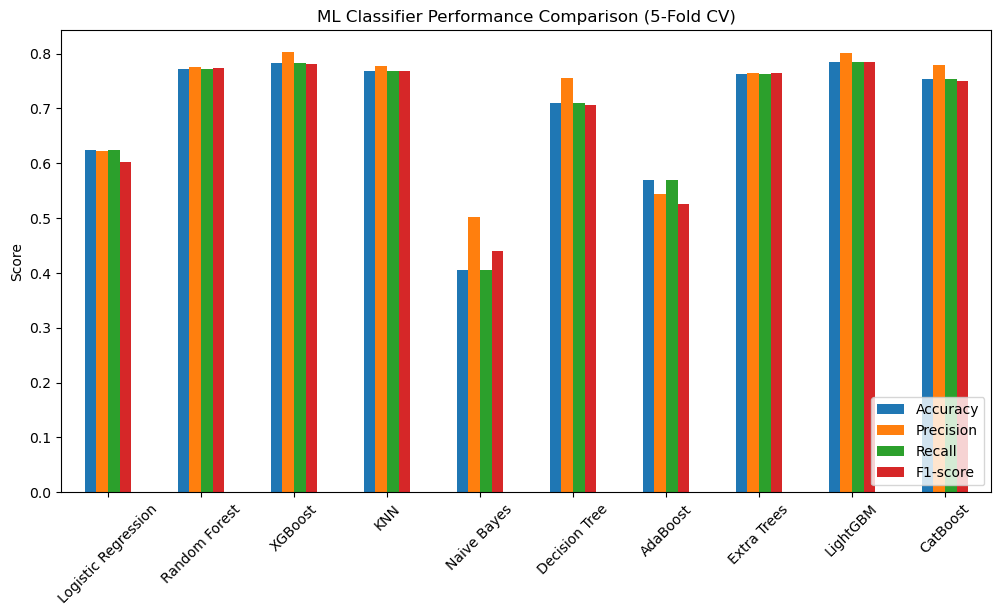

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
#